# Sleep Staging — 07: Model Comparison & Error Analysis

**Objetivo:** comparar los resultados finales de:

- baseline clásico de NB4;
- gradient boosting de NB5;
- 1D-CNN de NB6.

Los tres modelos se evalúan sobre exactamente el mismo holdout por sujeto.

Esta notebook **no entrena modelos**. Solo resume y analiza:

- métricas globales;
- métricas por etapa de sueño;
- matrices de confusión;
- desempeño según QC (`ok` / `review`);
- variabilidad entre sujetos.

La métrica principal sigue siendo **Macro-F1**.


---
## 1. Setup


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

RESULTS_DIR = Path("../reports/results")
FIGURES_DIR = Path("../reports/figures")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_METRICS_PATH = RESULTS_DIR / "baseline_holdout_metrics.json"
BOOSTING_METRICS_PATH = RESULTS_DIR / "boosting_holdout_metrics.json"
CNN_METRICS_PATH = RESULTS_DIR / "dl_cnn_holdout_metrics.json"

BASELINE_PRED_PATH = RESULTS_DIR / "baseline_holdout_predictions.parquet"
BOOSTING_PRED_PATH = RESULTS_DIR / "boosting_holdout_predictions.parquet"
CNN_PRED_PATH = RESULTS_DIR / "dl_cnn_holdout_predictions.parquet"

SUMMARY_PATH = RESULTS_DIR / "model_comparison_holdout.csv"
PER_STAGE_PATH = RESULTS_DIR / "model_comparison_per_stage.csv"
QC_PATH = RESULTS_DIR / "model_comparison_qc.csv"
SUBJECT_PATH = RESULTS_DIR / "model_comparison_per_subject.csv"

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

required_paths = [
    BASELINE_METRICS_PATH,
    BOOSTING_METRICS_PATH,
    CNN_METRICS_PATH,
    BASELINE_PRED_PATH,
    BOOSTING_PRED_PATH,
    CNN_PRED_PATH,
]

missing = [path for path in required_paths if not path.exists()]

if missing:
    missing_text = "\n".join(f" - {path}" for path in missing)
    raise FileNotFoundError(
        "Faltan resultados de NB4, NB5 o NB6. "
        "Ejecutá primero esas notebooks finales.\n"
        + missing_text
    )

print("Setup completado.")


Setup completado.


---
## 2. Carga y validación del holdout


In [2]:
with open(BASELINE_METRICS_PATH, "r", encoding="utf-8") as file:
    baseline_metrics = json.load(file)

with open(BOOSTING_METRICS_PATH, "r", encoding="utf-8") as file:
    boosting_metrics = json.load(file)

with open(CNN_METRICS_PATH, "r", encoding="utf-8") as file:
    cnn_metrics = json.load(file)

baseline_pred = pd.read_parquet(BASELINE_PRED_PATH)
boosting_pred = pd.read_parquet(BOOSTING_PRED_PATH)
cnn_pred = pd.read_parquet(CNN_PRED_PATH)

KEY_COLS = [
    "epoch_global",
    "subject",
    "source_epoch_index",
    "recording_onset_s",
]

REQUIRED_COLS = KEY_COLS + [
    "qc_status",
    "y_true",
    "y_pred",
]

prediction_tables = {
    "baseline": baseline_pred,
    "boosting": boosting_pred,
    "cnn": cnn_pred,
}

for name, df in prediction_tables.items():
    missing_cols = [
        col for col in REQUIRED_COLS
        if col not in df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Faltan columnas en predicciones de {name}: {missing_cols}"
        )

def prepare_predictions(df):
    return (
        df[REQUIRED_COLS]
        .sort_values(KEY_COLS)
        .reset_index(drop=True)
    )

baseline_cmp = prepare_predictions(baseline_pred)
boosting_cmp = prepare_predictions(boosting_pred)
cnn_cmp = prepare_predictions(cnn_pred)

if not (
    len(baseline_cmp)
    == len(boosting_cmp)
    == len(cnn_cmp)
):
    raise ValueError(
        "Los modelos tienen distinto número de epochs de test."
    )

for col in KEY_COLS + ["y_true", "qc_status"]:
    baseline_values = baseline_cmp[col].astype(str).to_numpy()

    if not np.array_equal(
        baseline_values,
        boosting_cmp[col].astype(str).to_numpy(),
    ):
        raise ValueError(
            f"Baseline y boosting no están alineados en: {col}"
        )

    if not np.array_equal(
        baseline_values,
        cnn_cmp[col].astype(str).to_numpy(),
    ):
        raise ValueError(
            f"Baseline y CNN no están alineados en: {col}"
        )

comparison_df = baseline_cmp[
    KEY_COLS + ["qc_status", "y_true"]
].copy()

comparison_df["baseline_pred"] = baseline_cmp["y_pred"].astype(np.int8)
comparison_df["boosting_pred"] = boosting_cmp["y_pred"].astype(np.int8)
comparison_df["cnn_pred"] = cnn_cmp["y_pred"].astype(np.int8)
comparison_df["y_true"] = comparison_df["y_true"].astype(np.int8)

print(f"Epochs de test:  {len(comparison_df)}")
print(f"Sujetos de test: {comparison_df['subject'].nunique()}")
print("NB4, NB5 y NB6 usan exactamente el mismo holdout.")


Epochs de test:  26632
Sujetos de test: 30
NB4, NB5 y NB6 usan exactamente el mismo holdout.


---
## 3. Comparación global


In [3]:
baseline_name = baseline_metrics.get(
    "experiment",
    "Baseline",
)

boosting_name = boosting_metrics.get(
    "model",
    "Boosting",
)

cnn_name = cnn_metrics.get(
    "model",
    "1D-CNN",
)

summary_df = pd.DataFrame([
    {
        "family": "Classical baseline",
        "model": baseline_name,
        "accuracy": baseline_metrics["accuracy"],
        "balanced_accuracy": baseline_metrics["balanced_accuracy"],
        "f1_macro": baseline_metrics["f1_macro"],
    },
    {
        "family": "Gradient boosting",
        "model": boosting_name,
        "accuracy": boosting_metrics["accuracy"],
        "balanced_accuracy": boosting_metrics["balanced_accuracy"],
        "f1_macro": boosting_metrics["f1_macro"],
    },
    {
        "family": "Deep learning",
        "model": cnn_name,
        "accuracy": cnn_metrics["accuracy"],
        "balanced_accuracy": cnn_metrics["balanced_accuracy"],
        "f1_macro": cnn_metrics["f1_macro"],
    },
]).sort_values(
    "f1_macro",
    ascending=False,
).reset_index(drop=True)

display(summary_df.round(4))

summary_df.to_csv(
    SUMMARY_PATH,
    index=False,
)


,family,model,accuracy,balanced_accuracy,f1_macro
0,Deep learning,1D-CNN,0.7437,0.7541,0.7359
1,Gradient boosting,LightGBM,0.7410,0.7330,0.7219
2,Classical baseline,Random Forest | All features,0.7343,0.7045,0.7011


---
## 4. Métricas por etapa de sueño


In [4]:
rows = []

model_predictions = {
    baseline_name: "baseline_pred",
    boosting_name: "boosting_pred",
    cnn_name: "cnn_pred",
}

for model_name, pred_col in model_predictions.items():

    report = classification_report(
        comparison_df["y_true"],
        comparison_df[pred_col],
        labels=STAGE_ORDER,
        target_names=STAGE_NAMES,
        output_dict=True,
        zero_division=0,
    )

    for stage in STAGE_NAMES:
        rows.append({
            "model": model_name,
            "stage": stage,
            "precision": report[stage]["precision"],
            "recall": report[stage]["recall"],
            "f1": report[stage]["f1-score"],
            "support": int(report[stage]["support"]),
        })

per_stage_df = pd.DataFrame(rows)

display(
    per_stage_df[
        ["model", "stage", "precision", "recall", "f1", "support"]
    ].round(4)
)

per_stage_df.to_csv(
    PER_STAGE_PATH,
    index=False,
)


,model,stage,precision,recall,f1,support
0,Random Forest | All features,W,0.7554,0.8277,0.7899,4354
1,Random Forest | All features,N1,0.4129,0.3552,0.3819,3043
2,Random Forest | All features,N2,0.7625,0.7563,0.7594,10169
3,Random Forest | All features,N3,0.7964,0.7966,0.7965,5014
4,Random Forest | All features,REM,0.7696,0.7865,0.7780,4052
5,LightGBM,W,0.7989,0.7774,0.7880,4354
6,LightGBM,N1,0.3863,0.4906,0.4323,3043
7,LightGBM,N2,0.8170,0.7071,0.7581,10169
8,LightGBM,N3,0.7853,0.8508,0.8168,5014
9,LightGBM,REM,0.7908,0.8388,0.8141,4052


---
## 5. Matrices de confusión


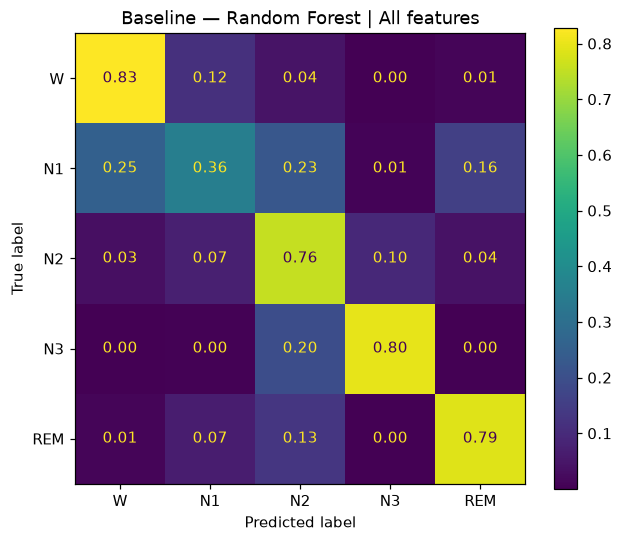

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    comparison_df["y_true"],
    comparison_df["baseline_pred"],
    labels=STAGE_ORDER,
    display_labels=STAGE_NAMES,
    normalize="true",
    values_format=".2f",
    ax=ax,
)

ax.set_title(f"Baseline — {baseline_name}")
fig.tight_layout()

baseline_cm_path = FIGURES_DIR / "nb7_baseline_confusion_matrix.png"
fig.savefig(baseline_cm_path, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(baseline_cm_path)))


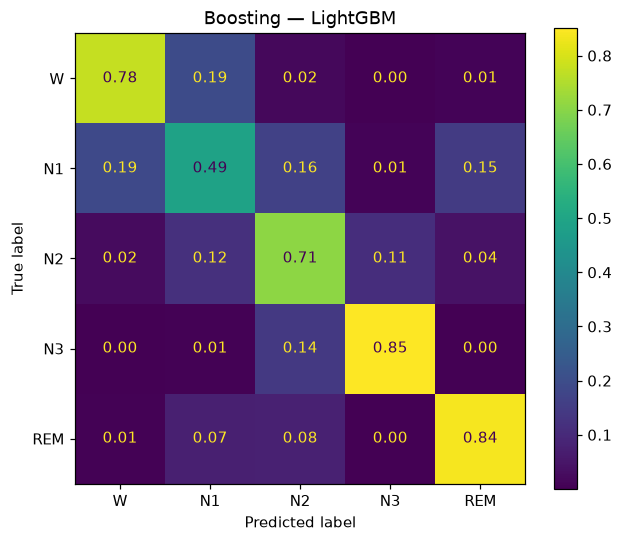

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    comparison_df["y_true"],
    comparison_df["boosting_pred"],
    labels=STAGE_ORDER,
    display_labels=STAGE_NAMES,
    normalize="true",
    values_format=".2f",
    ax=ax,
)

ax.set_title(f"Boosting — {boosting_name}")
fig.tight_layout()

boosting_cm_path = FIGURES_DIR / "nb7_boosting_confusion_matrix.png"
fig.savefig(boosting_cm_path, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(boosting_cm_path)))


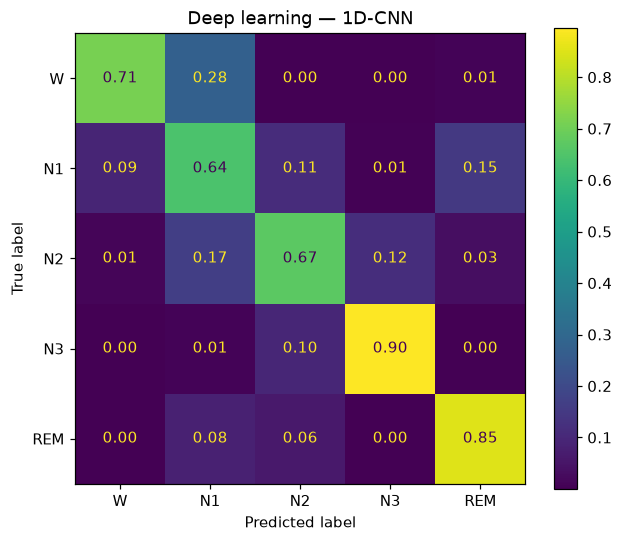

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    comparison_df["y_true"],
    comparison_df["cnn_pred"],
    labels=STAGE_ORDER,
    display_labels=STAGE_NAMES,
    normalize="true",
    values_format=".2f",
    ax=ax,
)

ax.set_title(f"Deep learning — {cnn_name}")
fig.tight_layout()

cnn_cm_path = FIGURES_DIR / "nb7_cnn_confusion_matrix.png"
fig.savefig(cnn_cm_path, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(cnn_cm_path)))


---
## 6. Desempeño según QC

Los epochs `review` fueron conservados en NB2. Aquí se verifica si resultan más difíciles de clasificar que los epochs `ok`.


In [8]:
qc_rows = []

for qc_value, group in comparison_df.groupby("qc_status"):
    for model_name, pred_col in model_predictions.items():

        qc_rows.append({
            "qc_status": qc_value,
            "model": model_name,
            "n_epochs": len(group),
            "accuracy": accuracy_score(
                group["y_true"],
                group[pred_col],
            ),
            "balanced_accuracy": balanced_accuracy_score(
                group["y_true"],
                group[pred_col],
            ),
            "f1_macro": f1_score(
                group["y_true"],
                group[pred_col],
                average="macro",
                zero_division=0,
            ),
        })

qc_df = pd.DataFrame(qc_rows)

display(
    qc_df.sort_values(
        ["qc_status", "f1_macro"],
        ascending=[True, False],
    ).round(4)
)

qc_df.to_csv(
    QC_PATH,
    index=False,
)


,qc_status,model,n_epochs,accuracy,balanced_accuracy,f1_macro
2,ok,1D-CNN,24209,0.7556,0.7563,0.7418
1,ok,LightGBM,24209,0.7526,0.7369,0.7283
0,ok,Random Forest | All features,24209,0.7431,0.7065,0.7061
5,review,1D-CNN,2423,0.6248,0.5788,0.5636
4,review,LightGBM,2423,0.6248,0.5064,0.5219
3,review,Random Forest | All features,2423,0.6471,0.4482,0.4831


---
## 7. Variabilidad entre sujetos

Se calcula Macro-F1 de manera independiente para cada sujeto del holdout.


In [9]:
subject_rows = []

for subject, group in comparison_df.groupby("subject"):
    for model_name, pred_col in model_predictions.items():

        subject_rows.append({
            "subject": subject,
            "model": model_name,
            "n_epochs": len(group),
            "f1_macro": f1_score(
                group["y_true"],
                group[pred_col],
                average="macro",
                zero_division=0,
            ),
        })

subject_df = pd.DataFrame(subject_rows)

subject_summary = (
    subject_df.groupby("model")["f1_macro"]
    .agg(["mean", "std", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

display(subject_summary.round(4))

subject_df.to_csv(
    SUBJECT_PATH,
    index=False,
)


,mean,std,median,min,max
model,,,,,
1D-CNN,0.7196,0.0920,0.7370,0.4395,0.8367
LightGBM,0.7103,0.1031,0.7345,0.4152,0.8399
Random Forest | All features,0.6784,0.1062,0.7212,0.4346,0.8183


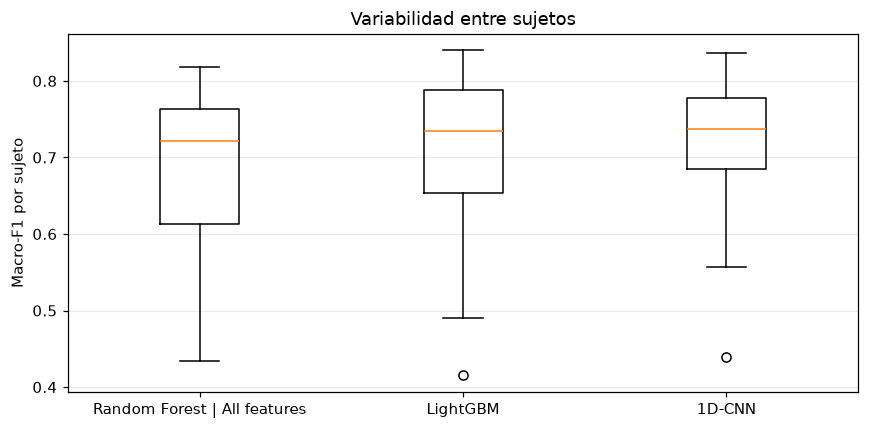

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))

models_in_order = [
    baseline_name,
    boosting_name,
    cnn_name,
]

values = [
    subject_df.loc[
        subject_df["model"] == model,
        "f1_macro",
    ].to_numpy()
    for model in models_in_order
]

ax.boxplot(
    values,
    tick_labels=models_in_order,
)

ax.set_ylabel("Macro-F1 por sujeto")
ax.set_title("Variabilidad entre sujetos")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

subject_fig_path = FIGURES_DIR / "nb7_subject_f1_distribution.png"
fig.savefig(subject_fig_path, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(subject_fig_path)))


---
## 8. Resumen final


In [11]:
best_global = summary_df.iloc[0]

checks = {
    "Mismo holdout en NB4, NB5 y NB6": (
        len(comparison_df)
        == len(baseline_cmp)
        == len(boosting_cmp)
        == len(cnn_cmp)
    ),
    "Comparación global guardada": SUMMARY_PATH.exists(),
    "Métricas por etapa guardadas": PER_STAGE_PATH.exists(),
    "Análisis QC guardado": QC_PATH.exists(),
    "Análisis por sujeto guardado": SUBJECT_PATH.exists(),
}

print("=" * 70)
print("CHECKLIST — COMPARACIÓN DE MODELOS")
print("=" * 70)

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'}  {label}")

print("\nMejor resultado global:")
print(f"  modelo:             {best_global['model']}")
print(f"  accuracy:           {best_global['accuracy']:.4f}")
print(f"  balanced accuracy:  {best_global['balanced_accuracy']:.4f}")
print(f"  Macro-F1:           {best_global['f1_macro']:.4f}")

print("\nPróximo paso:")
print(
    "  Incorporar contexto temporal entre epochs "
    "sobre la representación deep learning."
)


CHECKLIST — COMPARACIÓN DE MODELOS
✅  Mismo holdout en NB4, NB5 y NB6
✅  Comparación global guardada
✅  Métricas por etapa guardadas
✅  Análisis QC guardado
✅  Análisis por sujeto guardado

Mejor resultado global:
  modelo:             1D-CNN
  accuracy:           0.7437
  balanced accuracy:  0.7541
  Macro-F1:           0.7359

Próximo paso:
  Incorporar contexto temporal entre epochs sobre la representación deep learning.
